
# System predykcji zagrożenia finansowego<br>i ryzyka bankructwa przedsiębiorstw<br>z wykorzystaniem modeli uczenia maszynowego

### Autorzy: **Maria Wilgosz · Oliwia Marut · Martyna Czyż · Jakub Klimek**

# Rozdział 1: Wstęp

## 1.1 Cel projektu
bla bla czemu to robimy i wprowadzenie w temat o co chodzi

Przydatne zdania (?) Celem pracy jest zbadanie różnic między firmami oznaczonymi jako działające i upadłe oraz sprawdzenie, czy dostępne cechy finansowe pozwalają je rozróżnić za pomocą metod uczenia maszynowego.

## 1.2 Wykorzystane biblioteki

In [21]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Rozdział 2: Przedstawienie oraz przygotowanie danych

W projekcie wykorzystano zbiór American Bankruptcy Dataset, zawierający dane finansowe przedsiębiorstw z lat 1999–2018 oraz informacje o ich statusie. Zakres obejmuje opis kolumn, wczytanie pliku, sprawdzenie braków i duplikatów oraz uporządkowanie typów danych i kodowania statusu firmy.

## 2.1 Opis zbioru

Każdy wiersz opisuje jedną firmę w jednym roku obrotowym. Zbiór zawiera następujące kolumny:

- `company_name` — identyfikator firmy.
- `fyear` — rok obrotowy.
- `status_label` — status firmy: `alive` lub `failed`.
- `X1`–`X18` — wartości finansowe opisane poniżej.
- `Division`, `MajorGroup` — kody grup działalności. $\textbf{(POPRAW)}$

| Kod | Znaczenie | Kod | Znaczenie |
|---|---|---|---|
| X1 | Aktywa obrotowe — majątek wykorzystywany w krótkim okresie, np. zapasy, należności i gotówka. | X10 | Aktywa ogółem — łączna wartość majątku firmy. |
| X2 | Koszt własny sprzedaży — koszty sprzedanych produktów, towarów lub usług. | X11 | Dług długoterminowy — zadłużenie z terminem spłaty dłuższym niż rok. |
| X3 | Amortyzacja — rozłożony w czasie koszt zużycia majątku firmy. | X12 | EBIT — wynik finansowy przed uwzględnieniem odsetek i podatków. |
| X4 | EBITDA — wynik finansowy przed uwzględnieniem odsetek, podatków i amortyzacji. | X13 | Zysk brutto ze sprzedaży — przychody ze sprzedaży pomniejszone o koszt własny sprzedaży. |
| X5 | Zapasy — materiały, towary i produkty przeznaczone do wykorzystania lub sprzedaży. | X14 | Zobowiązania krótkoterminowe — zobowiązania do uregulowania zwykle w ciągu roku. |
| X6 | Wynik netto — ostateczny zysk lub strata po uwzględnieniu kosztów i podatków. | X15 | Zyski zatrzymane — skumulowane zyski pozostawione w firmie, pomniejszone o ewentualne straty. |
| X7 | Należności ogółem — kwoty, które inne podmioty powinny zapłacić firmie. | X16 | Przychody ogółem — łączne przychody uzyskane przez firmę. |
| X8 | Wartość rynkowa — wycena firmy na rynku, zwykle na podstawie wartości jej akcji. | X17 | Zobowiązania ogółem — suma zobowiązań krótko- i długoterminowych. |
| X9 | Sprzedaż netto — przychody ze sprzedaży po uwzględnieniu rabatów i zwrotów. | X18 | Koszty operacyjne — koszty związane z prowadzeniem działalności firmy. |


## 2.2. Kontrola jakości danych

W ramach wstępnej kontroli jakości danych sprawdzono występowanie brakujących wartości, zduplikowanych obserwacji oraz wartości nieskończonych w kolumnach liczbowych. Dodatkowo zweryfikowano, czy w zbiorze nie występują powtarzające się obserwacje dla tej samej pary przedsiębiorstwo–rok (`company_name`, `fyear`). Kontrola ta ma na celu wykrycie potencjalnych problemów mogących zaburzyć późniejszą analizę statystyczną oraz proces uczenia modeli.

In [3]:
df = pd.read_csv("american_bankruptcy_dataset.csv")

print("Łączna liczba braków:", df.isna().sum().sum())

print("Liczba duplikatów wierszy:", df.duplicated().sum())

print(
    "Duplikaty przedsiębiorstwo-rok:",
    df.duplicated(subset=["company_name", "fyear"]).sum()
)

kolumny_liczbowe = df.select_dtypes(include="number")

print(
    "Liczba wartości nieskończonych:",
    np.isinf(kolumny_liczbowe).sum().sum()
)

display(df.isna().sum().to_frame("Liczba braków"))

Łączna liczba braków: 0
Liczba duplikatów wierszy: 0
Duplikaty przedsiębiorstwo-rok: 0
Liczba wartości nieskończonych: 0


,Liczba braków
company_name,0
fyear,0
status_label,0
X1,0
X2,0
X3,0
X4,0
X5,0
X6,0
X7,0


W przeprowadzonej kontroli nie wykryto brakujących wartości w żadnej z kolumn zbioru. Nie stwierdzono również duplikatów obserwacji ani wartości nieskończonych, co pozwala uznać dane za kompletne i spójne na tym etapie analizy.

# Rozdział 3: Analiza danych finansowych

W rozdziale tym przeprowadzona zostanie analiza matematyczna i statystyczna danych finansowych zawartych w zbiorze. Celem będzie lepsze poznanie struktury danych, sposobu zachowania poszczególnych parametrów oraz ich zróżnicowania w badanej próbie.

Analiza obejmie również ocenę zależności występujących pomiędzy zmiennymi oraz identyfikację cech, które mogą mieć znaczenie w kontekście rozróżniania przedsiębiorstw o różnym statusie finansowym. Uzyskane wyniki będą stanowiły podstawę do dalszego przygotowania danych i budowy modeli uczenia maszynowego.

## 3.1 Rozkład klas alive i failed

Na początku analizy warto określić, jak w zbiorze rozkładają się obserwacje pomiędzy klasami alive i failed. Pozwala to ocenić, czy obie grupy są reprezentowane w podobnym stopniu, czy też jedna z nich zdecydowanie dominuje.

Jest to szczególnie istotne z punktu widzenia późniejszego modelowania, ponieważ duża różnica w liczebności klas może wpływać na sposób uczenia modeli oraz ocenę ich skuteczności. W poniższym zestawieniu przedstawiono liczbę obserwacji oraz procentowy udział każdej klasy w całym zbiorze danych.

,Liczba obserwacji,Udział (%)
status_label,,
alive,73462,93.37
failed,5220,6.63


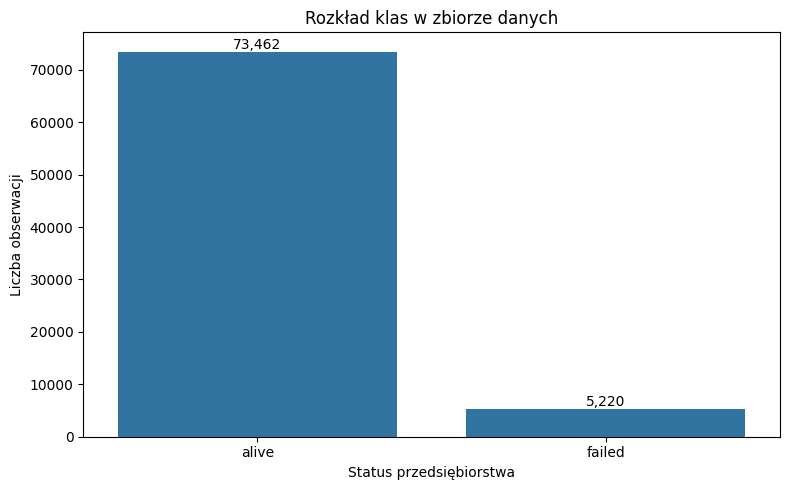

In [22]:
liczebnosci = df["status_label"].value_counts()
procenty = df["status_label"].value_counts(normalize=True) * 100

display(pd.DataFrame({
    "Liczba obserwacji": liczebnosci,
    "Udział (%)": procenty.round(2)
}))

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="status_label",
    order=["alive", "failed"]
)

for p in ax.patches:
    ax.annotate(
        f"{int(p.get_height()):,}",
        (p.get_x() + p.get_width()/2, p.get_height()),
        ha="center",
        va="bottom"
    )

plt.title("Rozkład klas w zbiorze danych")
plt.xlabel("Status przedsiębiorstwa")
plt.ylabel("Liczba obserwacji")
plt.tight_layout()
plt.show()

### Wnioski
W zbiorze znajduje się 73 462 obserwacji oznaczonych jako `alive` oraz 5 220 obserwacji `failed`. Odpowiada to odpowiednio około 93,37% i 6,63% wszystkich rekordów.

Rozkład klas jest więc nierównomierny, co należy uwzględnić w dalszej analizie oraz podczas budowy i oceny modeli uczenia maszynowego. W szczególności warto zwrócić uwagę na to, jak dobrze model radzi sobie z poprawnym rozpoznawaniem mniej licznej klasy failed.

## 3.2. Analiza bankructw w latach 1999–2018

W kolejnym kroku przeanalizowano, jak liczba oraz udział obserwacji oznaczonych jako `failed` zmieniały się w kolejnych latach badanego okresu. Pozwala to ocenić, czy przypadki bankructwa były rozłożone równomiernie w czasie, czy też w wybranych latach występowały częściej.

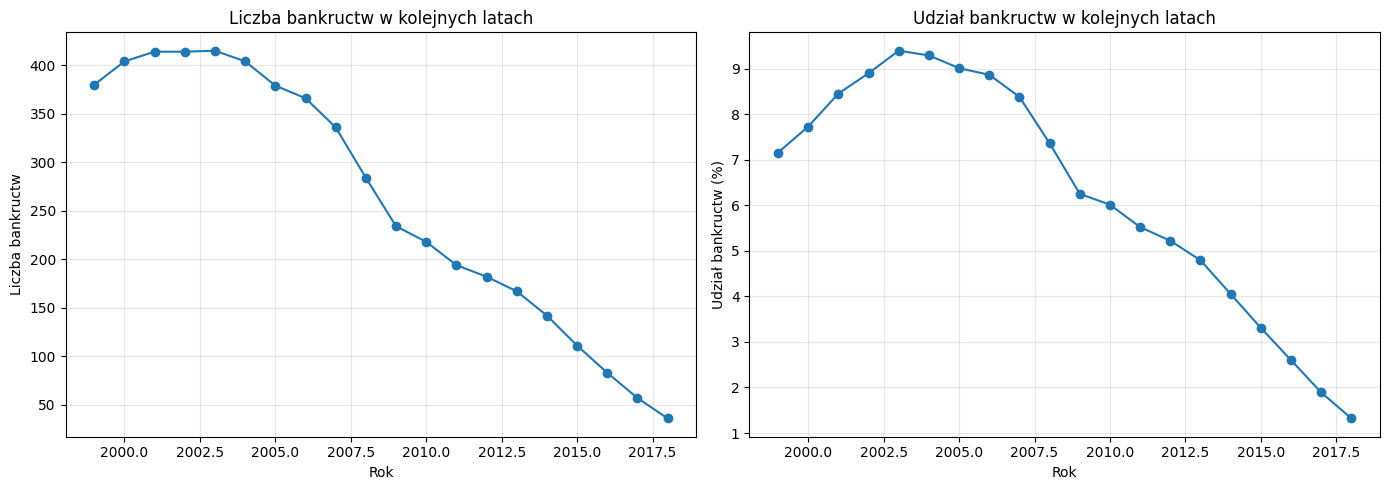

In [32]:
bankructwa_lata = df.groupby("fyear").agg(
    liczba_firm=("company_name", "count"),
    bankructwa=("status_label", lambda x: (x == "failed").sum())
)

bankructwa_lata["procent"] = (
    bankructwa_lata["bankructwa"]
    / bankructwa_lata["liczba_firm"] * 100
)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# liczba bankructw
ax[0].plot(
    bankructwa_lata.index,
    bankructwa_lata["bankructwa"],
    marker="o"
)

ax[0].set_title("Liczba bankructw w kolejnych latach")
ax[0].set_xlabel("Rok")
ax[0].set_ylabel("Liczba bankructw")
ax[0].grid(alpha=0.3)

# procent bankructw
ax[1].plot(
    bankructwa_lata.index,
    bankructwa_lata["procent"],
    marker="o"
)

ax[1].set_title("Udział bankructw w kolejnych latach")
ax[1].set_xlabel("Rok")
ax[1].set_ylabel("Udział bankructw (%)")
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 3.1 Statystyki opisowe parametrów finansowych

W celu wstępnego scharakteryzowania zmiennych finansowych przeprowadzona zostanie analiza podstawowych statystyk opisowych dla parametrów X1–X18. Jej celem jest określenie skali poszczególnych zmiennych, ich zróżnicowania oraz sposobu rozłożenia wartości w całym zbiorze danych.

Dla każdego parametru zostaną zestawione takie miary jak średnia, mediana, odchylenie standardowe, kwartyle oraz wartości minimalne i maksymalne. Pozwoli to wskazać zmienne o dużej zmienności, zauważyć ewentualne wartości skrajne oraz ocenić, w których przypadkach rozkład danych może być silnie asymetryczny.

Zestawienie wszystkich parametrów w jednej tabeli umożliwi również ich porównanie pod względem skali i rozrzutu wartości. Wyniki tej analizy będą stanowiły punkt wyjścia do dalszego badania różnic pomiędzy firmami oznaczonymi jako alive i failed oraz zależności występujących pomiędzy poszczególnymi cechami finansowymi.

In [4]:
# wybór parametrów finansowych
parametry = [f"X{i}" for i in range(1, 19)]

# opis parametrów
nazwy_parametrow = {
    "X1": "X1 (Aktywa obrotowe)",
    "X2": "X2 (Koszt własny sprzedaży)",
    "X3": "X3 (Amortyzacja)",
    "X4": "X4 (EBITDA)",
    "X5": "X5 (Zapasy)",
    "X6": "X6 (Wynik netto)",
    "X7": "X7 (Należności ogółem)",
    "X8": "X8 (Wartość rynkowa)",
    "X9": "X9 (Sprzedaż netto)",
    "X10": "X10 (Aktywa ogółem)",
    "X11": "X11 (Dług długoterminowy)",
    "X12": "X12 (EBIT)",
    "X13": "X13 (Zysk brutto ze sprzedaży)",
    "X14": "X14 (Zobowiązania krótkoterminowe)",
    "X15": "X15 (Zyski zatrzymane)",
    "X16": "X16 (Przychody ogółem)",
    "X17": "X17 (Zobowiązania ogółem)",
    "X18": "X18 (Koszty operacyjne)"
}

# tabela statystyk opisowych
tabela_statystyk = pd.DataFrame({
    "Średnia": df[parametry].mean(),
    "Mediana": df[parametry].median(),
    "Odch.std": df[parametry].std(),
    "Q1": df[parametry].quantile(0.25),
    "Q3": df[parametry].quantile(0.75),
    "Min": df[parametry].min(),
    "Max": df[parametry].max()
})

# zmiana nazw parametrów w indeksie
tabela_statystyk.index = tabela_statystyk.index.map(nazwy_parametrow)
tabela_statystyk.index.name = "Parametr"

tabela_statystyk.round(2)

,Średnia,Mediana,Odch.std,Q1,Q3,Min,Max
Parametr,,,,,,,
X1 (Aktywa obrotowe),213314.08,22016.50,701629.10,1272.00,153994.00,-2498.00,31322583.0
X2 (Koszt własny sprzedaży),599470.89,43266.50,2065451.51,3282.52,329362.00,0.01,67234944.0
X3 (Amortyzacja),379774.46,21044.50,2021659.41,1439.10,180821.50,-366645.00,163245615.0
X4 (EBITDA),150843.34,500.00,711505.23,0.00,16010.50,-23.00,20687082.0
X5 (Zapasy),24715.65,1216.00,97781.69,74.40,12344.75,0.00,4440438.0
X6 (Wynik netto),44261.77,303.00,224001.73,-767.75,19097.75,-5043795.00,9783515.0
X7 (Należności ogółem),69421.15,1121.90,284799.37,-9.00,33256.75,-4512135.00,12566722.0
X8 (Wartość rynkowa),172375.67,11459.50,600752.29,355.43,109900.00,-4367571.00,27864399.0
X9 (Sprzedaż netto),51021.66,675.00,220407.62,0.00,16771.75,0.00,11918508.0


### Wnioski ze statystyk opisowych

Zestawione statystyki opisowe wskazują na bardzo duże zróżnicowanie wartości poszczególnych parametrów finansowych. W przypadku wielu zmiennych średnia jest wyraźnie większa od mediany, co sugeruje występowanie rozkładów silnie asymetrycznych oraz pojedynczych obserwacji o bardzo dużych wartościach. Jest to szczególnie widoczne m.in. dla EBITDA (`X4`), zysków zatrzymanych (`X15`), aktywów ogółem (`X10`) czy przychodów ogółem (`X16`). Oznacza to, że w zbiorze znajdują się przedsiębiorstwa bardzo różniące się skalą działalności, dlatego sama średnia nie zawsze będzie dobrą miarą wartości typowej.

Duże wartości odchylenia standardowego również potwierdzają znaczny rozrzut danych. Szczególnym przykładem jest `X15` (zyski zatrzymane), dla którego mediana wynosi około 373, podczas gdy wartość maksymalna przekracza 467 mln. Podobne, choć mniej skrajne, różnice występują także w innych parametrach. W dalszej analizie zasadne będzie zatem dokładniejsze sprawdzenie rozkładów oraz obserwacji odstających.

Warto zwrócić uwagę na parametry, które przyjmują zarówno wartości dodatnie, jak i ujemne. `X6` (wynik netto) ma pierwszy kwartyl poniżej zera, co oznacza, że znaczna część obserwacji dotyczy przedsiębiorstw wykazujących stratę. Jeszcze ciekawszy jest `X12` (EBIT), którego mediana jest lekko ujemna, a wartości rozciągają się od dużych strat do bardzo wysokich wyników dodatnich. Parametry te mogą być szczególnie interesujące przy późniejszym porównaniu przedsiębiorstw `alive` oraz `failed`.

W danych widoczne są również wartości wymagające dodatkowej weryfikacji. Niektóre zmienne posiadają nietypowe wartości minimalne, w tym wartości ujemne w parametrach, dla których z ekonomicznego punktu widzenia mogą one wymagać dodatkowego wyjaśnienia. Przed wykorzystaniem danych w modelach uczenia maszynowego należy więc sprawdzić konkretne rekordy i ustalić, czy wynikają one ze sposobu raportowania danych, zastosowanej konwencji księgowej czy też stanowią obserwacje nietypowe.

Szczególną uwagę zwracają parametry `X14` oraz `X17`. Ich średnia, mediana, odchylenie standardowe, kwartyle, minimum oraz maksimum są identyczne. Samo zestawienie statystyk nie pozwala stwierdzić, że kolumny są identyczne, jednak podobieństwo to jest na tyle duże, że należy sprawdzić zależność pomiędzy nimi bezpośrednio w danych. Jeżeli wartości obu parametrów okażą się takie same dla wszystkich obserwacji, będzie to istotne przy późniejszej analizie korelacji i doborze cech do modelu.

Na tym etapie statystyki opisowe pozwalają przede wszystkim scharakteryzować strukturę zbioru, zmienność parametrów oraz wskazać potencjalnie nietypowe obserwacje. Nie pozwalają jeszcze jednoznacznie określić, które zmienne są najważniejsze z punktu widzenia predykcji bankructwa. W kolejnym etapie konieczne będzie porównanie rozkładów poszczególnych parametrów pomiędzy przedsiębiorstwami oznaczonymi jako `alive` i `failed`, a następnie analiza zależności pomiędzy zmiennymi. Dopiero takie zestawienie pozwoli ocenić, które cechy mogą wnosić istotną informację do późniejszego modelu predykcyjnego.

### 3.2 Weryfikacja zgodności parametrów X14 i X17

Ze względu na identyczne wartości podstawowych statystyk opisowych dla parametrów `X14` i `X17`, przeprowadzono bezpośrednie porównanie obu kolumn. Celem jest sprawdzenie, czy zgodność dotyczy jedynie statystyk zbiorczych, czy też wartości obu parametrów są identyczne dla wszystkich obserwacji w zbiorze danych.

In [6]:
# sprawdzenie, czy wszystkie wartości X14 i X17 są identyczne
czy_identyczne = df["X14"].equals(df["X17"])

print("Czy X14 i X17 są identyczne:", czy_identyczne)

liczba_roznic = (df["X14"] != df["X17"]).sum()

print("Liczba różniących się rekordów:", liczba_roznic)

Czy X14 i X17 są identyczne: True
Liczba różniących się rekordów: 0


### Wnioski z porównania parametrów X14 i X17

Porównanie parametrów `X14` i `X17` wykazało, że ich wartości są identyczne dla wszystkich obserwacji w zbiorze danych. Oznacza to, że z punktu widzenia dalszej analizy obie zmienne przekazują tę samą informację.

Aby uniknąć powielania identycznej cechy w kolejnych etapach analizy oraz w modelach uczenia maszynowego, w dalszej części projektu wykorzystywana będzie tylko jedna z tych zmiennych. Będzie ona opisywana jako **„Zobowiązania (X14/X17)”**.

# te 2 kody nizej to glowne wnioski z analizy czy mamy te niepoprawne kolumny, na razie zostawiam tak, aby o tym pamietac


In [8]:
podejrzane_kolumny = ["X1", "X8", "X11", "X14", "X17"]

for kolumna in podejrzane_kolumny:
    liczba_ujemnych = (df[kolumna] < 0).sum()
    print(f"{kolumna}: {liczba_ujemnych} wartości ujemnych")

X1: 6 wartości ujemnych
X8: 6603 wartości ujemnych
X11: 34001 wartości ujemnych
X14: 13 wartości ujemnych
X17: 13 wartości ujemnych


In [16]:
firma_min_x8 = najmniejszy_x8["company_name"]

historia_firmy = (
    df[df["company_name"] == firma_min_x8]
    [["company_name", "fyear", "status_label", "X8"]]
    .sort_values("fyear")
)

historia_firmy

,company_name,fyear,status_label,X8
30035,C_2893,1999.0,alive,51538.000
30036,C_2893,2000.0,alive,132178.000
30037,C_2893,2001.0,alive,197828.000
30038,C_2893,2002.0,alive,196525.000
30039,C_2893,2003.0,alive,269642.000
30040,C_2893,2004.0,alive,320002.000
30041,C_2893,2005.0,alive,388569.000
30042,C_2893,2006.0,alive,474468.000
30043,C_2893,2007.0,alive,633.209
30044,C_2893,2008.0,alive,698.976


In [37]:
firma_c998 = (
    df[df["company_name"] == "C_998"]
    .sort_values("fyear")
)

display(firma_c998)

,company_name,fyear,status_label,X1,X2,X3,X4,X5,X6,X7,...,X11,X12,X13,X14,X15,X16,X17,X18,Division,MajorGroup
11886,C_998,1999.0,failed,1468808.000,3874891.000,1583195.000,323014.000,67649.000,87.409,155058.000,...,0.440,-255884.000,850888.000,1891088.000,540.3425,3083005.000,1891088.000,1736.030,D,34
11887,C_998,2000.0,failed,574528.000,2025126.000,1603771.000,323157.000,63.890,14865.000,78755.000,...,-22082.000,-285754.000,268766.000,1877753.000,651.2028,1248523.000,1877753.000,1798.998,D,34
11888,C_998,2001.0,failed,799.499,2103.840,1715677.000,100393.000,60.440,49988.000,110428.000,...,-20022.000,-308035.000,253957.000,1969806.000,757.3903,1333.730,1969806.000,1859378.000,D,34
11889,C_998,2002.0,failed,762905.000,1278171.000,1703.327,86104.000,40811.000,-155931.000,-115.120,...,-776.394,-1513744.000,289289.000,1748681.000,281.5902,1694928.000,1748681.000,1863801.000,D,34
11890,C_998,2003.0,failed,698.527,1248874.000,2208338.000,279682.000,44504.000,-87242.000,-42738.000,...,-95229.000,-1474342.000,253585.000,2335364.000,789.5126,1612.051,2335364.000,2378.102,D,34
11891,C_998,2004.0,failed,799923.000,1386932.000,1633629.000,268011.000,40293.000,45835.000,86.128,...,61639.000,-1388434.000,333704.000,1923019.000,1234.1408,1648375.000,1923019.000,1836891.000,D,34
11892,C_998,2005.0,failed,993099.000,1668286.000,1413105.000,207861.000,44.266,176514.000,220.780,...,197977.000,-1283783.000,322435.000,1856311.000,3203.1318,1751.584,1856311.000,1635531.000,D,34
11893,C_998,2006.0,failed,2140478.000,3594187.000,3305921.000,15242.000,61.000,364696.000,425696.000,...,342.299,-879.218,755683.000,4120141.000,5639.6111,3205807.000,4120141.000,3694445.000,D,34
11894,C_998,2007.0,failed,2757.500,4411486.000,4404.908,10.609,95989.000,666102.000,762091.000,...,607828.000,-146644.000,843.489,5631.610,13333.1061,3244481.000,5631.610,4869519.000,D,34
11895,C_998,2008.0,failed,2216985.000,4601693.000,5393694.000,6109.000,126133.000,464649.000,590.782,...,429302.000,-107824.000,852.621,6527523.000,2255.9399,3285521.000,6527523.000,5936741.000,D,34


In [39]:
ostatni_failed = (
    df[df["status_label"] == "failed"]
    .groupby("company_name")["fyear"]
    .max()
    .sort_values()
)

display(ostatni_failed)

company_name
C_1778    1999.0
C_4754    1999.0
C_2288    1999.0
C_1667    2000.0
C_4727    2000.0
           ...  
C_1440    2018.0
C_8325    2018.0
C_8371    2018.0
C_8385    2018.0
C_1251    2018.0
Name: fyear, Length: 609, dtype: float64

ostatnie failed, tez do testu czy dane sa ok(Nie sa)

In [40]:
ostatni_failed_lata = (
    ostatni_failed
    .value_counts()
    .sort_index()
)

display(ostatni_failed_lata)

fyear
1999.0     3
2000.0     7
2001.0    10
2002.0    17
2003.0    29
2004.0    46
2005.0    40
2006.0    51
2007.0    59
2008.0    58
2009.0    23
2010.0    35
2011.0    25
2012.0    26
2013.0    28
2014.0    33
2015.0    33
2016.0    29
2017.0    21
2018.0    36
Name: count, dtype: int64